In [8]:
import cv2 as cv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import skimage as ski

import numpy.ma as ma
# import cupy as cp

import scipy as sp

import statistics as st

from itertools import cycle

# from sklearn.preprocessing import minmax_scale
import pandas as pd

from scipy import ndimage as ndi
from skimage.feature import peak_local_max

import mpl_toolkits as mpl

from pathlib import Path

import seaborn as sns

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers


%matplotlib inline

In [7]:
import api

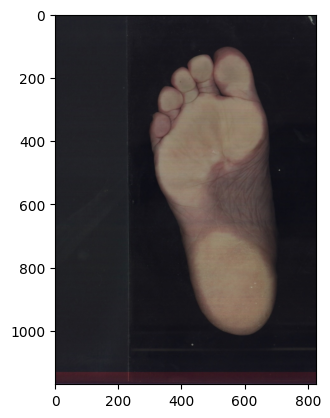

In [3]:
result = api.get_image_and_mask('../annotations.xml', image_id=1, label='foot')

plt.imshow(result.image, 'gray')

In [60]:
kernel = tf.constant([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1],
])

model = keras.Sequential([
    layers.Input(shape=(8, 8, 1), batch_size=1, name='Input'),
    layers.Dense(
        units=1,
        # kernel_initializer=initializers.RandomNormal(stddev=0.01),
        kernel_initializer=keras.initializers.Zeros(),
        bias_initializer=keras.initializers.Zeros()
    ),
    layers.Conv2D(filters=1, kernel_size=3), # activation is None
    # More layers follow
])

In [29]:
img = tf.convert_to_tensor(ski.util.img_as_float32(result.image), dtype=tf.float32)


In [30]:
if len(img.shape) == 3:
    inp = tf.expand_dims(img, axis=0)
else:
    raise Exception('source img shape doesn\'t have exactly 3 dimensions')

img.shape

TensorShape([1170, 827, 3])

In [64]:
inp = tf.constant(np.arange(64).reshape(8, 8, 1), dtype=tf.float32)
inp = tf.expand_dims(inp, axis=0)

# print(inp)

print(model.layers[0].get_weights()[0])

print(model(inp))


[[0.]]
tf.Tensor(
[[[[0.]
   [0.]
   [0.]
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   [0.]
   [0.]
   [0.]]

  [[0.]
   [0.]
   [0.]
   [0.]
   [0.]
   [0.]]]], shape=(1, 6, 6, 1), dtype=float32)


In [91]:
inp = np.arange(10)
weights = np.random.rand((10)) - 0.5

print(inp, inp.shape)
print(weights, weights.shape)

y = np.matmul(inp, weights)

relu = lambda x: np.max([0, x])


print(y, relu(y))

[0 1 2 3 4 5 6 7 8 9] (10,)
[-0.26209199 -0.3040149   0.06948097  0.26737922  0.12521242  0.35626952
 -0.10927353  0.49533201 -0.01165893 -0.07833388] (10,)
4.932688549157788 4.932688549157788
